1. Data Preprocessing

In [17]:
import nltk

nltk.download('gutenberg')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import gutenberg

train_text_caesar = gutenberg.raw('shakespeare-caesar.txt')
train_text_macbeth = gutenberg.raw('shakespeare-macbeth.txt')

train_text = train_text_caesar + " " + train_text_macbeth
eval_text = gutenberg.raw('shakespeare-hamlet.txt')

print(f"Training text length: {len(train_text)} characters")
print(f"Evaluation text length: {len(eval_text)} characters")

Training text length: 212662 characters
Evaluation text length: 162881 characters


[nltk_data] Downloading package gutenberg to /home/youssef-
[nltk_data]     khamis/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to /home/youssef-
[nltk_data]     khamis/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/youssef-
[nltk_data]     khamis/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [18]:
from collections import Counter
from nltk.corpus import gutenberg

train_sents_raw = gutenberg.sents('shakespeare-caesar.txt') + gutenberg.sents('shakespeare-macbeth.txt')
eval_sents_raw = gutenberg.sents('shakespeare-hamlet.txt')


UNK, BOS, EOS = '<UNK>', '<s>', '</s>'


def clean_and_pad(sents):
    processed = []
    for sent in sents:
        cleaned = [w.lower() for w in sent if w.isalpha()]
        if cleaned:
            processed.append([BOS] + cleaned + [EOS])
    return processed

train_sents = clean_and_pad(train_sents_raw)
eval_sents = clean_and_pad(eval_sents_raw)

word_counts = Counter(w for s in train_sents for w in s)
vocab = {w for w, c in word_counts.items() if c >= 2}
vocab |= {UNK, BOS, EOS}

def map_unk(sents, vocab):
    return [[w if w in vocab else UNK for w in s] for s in sents]

train_sents = map_unk(train_sents, vocab)
eval_sents  = map_unk(eval_sents, vocab)

print("Vocab size:", len(vocab))
print("Eval <UNK> rate:", round(sum(w == UNK for s in eval_sents for w in s) /
                                sum(len(s) for s in eval_sents), 3))

train_tokens = [w for s in train_sents for w in s]
eval_tokens = [w for s in eval_sents for w in s]

Vocab size: 2323
Eval <UNK> rate: 0.156


In [19]:
nltk.download('stopwords')
from nltk.corpus import stopwords

def remove_stopwords(tokens):
    stop_words = set(stopwords.words('english'))
    filtered_tokens = [word for word in tokens if word not in stop_words]

    return filtered_tokens

train_tokens = remove_stopwords(train_tokens)
eval_tokens = remove_stopwords(eval_tokens)

print(f"Training tokens after stopwords removal: {len(train_tokens)}")
print(f"Sample after stopwords: {train_tokens[:10]}")

Training tokens after stopwords removal: 29110
Sample after stopwords: ['<s>', 'tragedie', '<UNK>', 'caesar', 'william', 'shakespeare', '</s>', '<s>', 'actus', 'primus']


[nltk_data] Downloading package stopwords to /home/youssef-
[nltk_data]     khamis/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [20]:
from collections import Counter

class UnigramModel:
    def __init__(self):
        self.counts = Counter()
        self.total_tokens = 0
        self.vocab = set()

    def train(self, tokens):
        # Count occurrences of each word
        self.counts.update(tokens)
        self.total_tokens = len(tokens)
        self.vocab = set(self.counts.keys())

    def get_prob(self, word):
        if self.total_tokens == 0:
            return 0.0
        return self.counts[word] / self.total_tokens

unigram_baseline = UnigramModel()
unigram_baseline.train(train_tokens)

print(f"Vocabulary size: {len(unigram_baseline.vocab)}")
print(f"Unigram P('king'): {unigram_baseline.get_prob('king'):.6f}")

Vocabulary size: 2218
Unigram P('king'): 0.002027


In [21]:
def extract_ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens)-n+1)]

# Example
n_size = 2
ngram_counts = Counter(extract_ngrams(train_tokens, n_size))

# The context for a bigram is the previous 1 word (unigram)
context_counts = Counter(extract_ngrams(train_tokens, n_size-1))

print(f"Top 5 most common {n_size}-grams:")
for ngram, count in ngram_counts.most_common(5):
    print(f"{ngram}: {count}")

Top 5 most common 2-grams:
('</s>', '<s>'): 3985
('<UNK>', '<UNK>'): 507
('<UNK>', '</s>'): 311
('<s>', '<UNK>'): 180
('bru', '</s>'): 153


In [22]:
class SmoothedNGramModel:
    def __init__(self, n, k=1):
        self.n = n       # N-gram size (1 for unigram, 2 for bigram, etc.)
        self.k = k       # Laplace smoothing constant (usually 1)
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.vocab = set()
        self.vocab_size = 0

    def train(self, tokens):
        self.vocab = set(tokens)
        self.vocab_size = len(self.vocab)

        # Count N-grams
        ngrams = [tuple(tokens[i:i+self.n]) for i in range(len(tokens)-self.n+1)]
        self.ngram_counts.update(ngrams)

        # Count Contexts (N-1 grams)
        if self.n > 1:
            contexts = [tuple(tokens[i:i+self.n-1]) for i in range(len(tokens)-self.n+1)]
            self.context_counts.update(contexts)
        else:
            self.context_counts[''] = len(tokens)

    def get_prob(self, ngram):
        ngram_count = self.ngram_counts[ngram]

        if self.n > 1:
            context = ngram[:-1]
            context_count = self.context_counts[context]
        else:
            context_count = self.context_counts['']

        prob = (ngram_count + self.k) / (context_count + self.k * self.vocab_size)
        return prob

smoothed_bigram = SmoothedNGramModel(n=2, k=1)
smoothed_bigram.train(train_tokens)

test_ngram = ('caesar', 'laptop')
print(f"Smoothed P{test_ngram}: {smoothed_bigram.get_prob(test_ngram):.8f}")

Smoothed P('caesar', 'laptop'): 0.00041511


In [23]:
import random

def generate_text(model, start_context, max_words=30):
    if model.n == 1:
        current_context = ()
        generated_words = []
    else:
        current_context = tuple(start_context)
        generated_words = list(start_context)

    vocab_list = list(model.vocab)

    for _ in range(max_words):

        probs = [model.get_prob(current_context + (w,)) for w in vocab_list]
        next_word = random.choices(vocab_list, weights=probs, k=1)[0]
        generated_words.append(next_word)
        if model.n > 1:
            current_context = tuple(generated_words[-(model.n-1):])

    return ' '.join(generated_words)

start_seed = ('the',)
generated_sentence = generate_text(smoothed_bigram, start_context=start_seed, max_words=20)

print("Generated Text:")
print(generated_sentence)

Generated Text:
the ioyn second glad stay fold well alas falles prickt dangers new mistrust lena gouerne proofe capitoll yet something temple proceeding


In [24]:

# Initialize and train a trigram model (n=3) as a primary example
n_size_eval = 3
trigram_model = SmoothedNGramModel(n=n_size_eval, k=1)

print(f"Training {n_size_eval}-gram model on training corpus...")
trigram_model.train(train_tokens)

print("Training complete.")
print(f"Vocabulary size learned: {trigram_model.vocab_size}")


Training 3-gram model on training corpus...
Training complete.
Vocabulary size learned: 2218


In [25]:
import math

def calculate_perplexity(model, tokens):
    # Extract N-grams from the evaluation tokens
    eval_ngrams = [tuple(tokens[i:i+model.n]) for i in range(len(tokens)-model.n+1)]

    N = len(eval_ngrams)
    if N == 0:
        return float('inf')

    log_prob_sum = 0.0

    for ngram in eval_ngrams:
        prob = model.get_prob(ngram)

        log_prob_sum += math.log(prob)


    perplexity = math.exp(-log_prob_sum / N)
    return perplexity

pp_score = calculate_perplexity(trigram_model, eval_tokens)
print(f"Perplexity of {trigram_model.n}-gram model on evaluation corpus: {pp_score:.2f}")

Perplexity of 3-gram model on evaluation corpus: 617.03


Evaluating N-gram models from n=1 to n=10...
n=1 | Perplexity: 98.01
n=2 | Perplexity: 192.80
n=3 | Perplexity: 617.03
n=4 | Perplexity: 1232.79
n=5 | Perplexity: 1745.31
n=6 | Perplexity: 2157.66
n=7 | Perplexity: 2209.75
n=8 | Perplexity: 2215.19
n=9 | Perplexity: 2216.56
n=10 | Perplexity: 2217.24


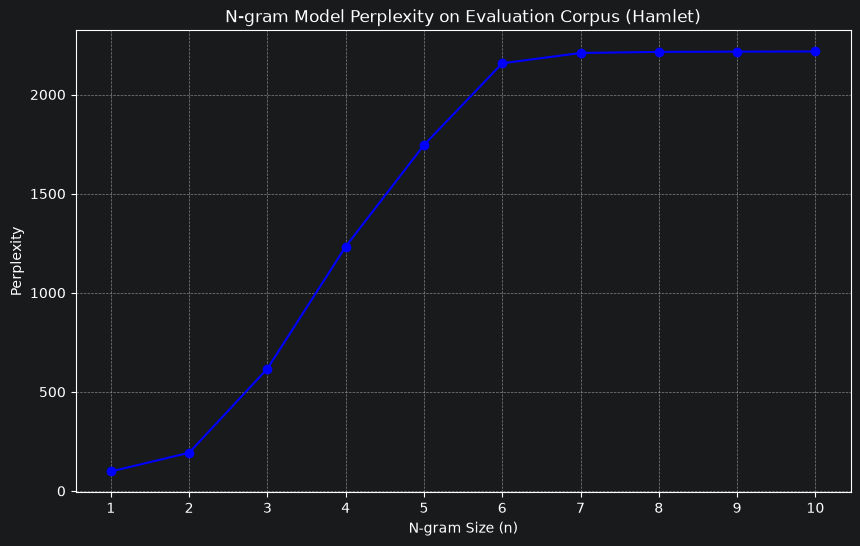

In [26]:
import matplotlib.pyplot as plt


max_n = 10
n_values = list(range(1, max_n + 1))
perplexities = []

print("Evaluating N-gram models from n=1 to n=10...")
for n in n_values:
    model = SmoothedNGramModel(n=n, k=1)
    model.train(train_tokens)

    pp = calculate_perplexity(model, eval_tokens)
    perplexities.append(pp)

    print(f"n={n} | Perplexity: {pp:.2f}")

# Plot the comparison results
plt.figure(figsize=(10, 6))
plt.plot(n_values, perplexities, marker='o', linestyle='-', color='b')
plt.title("N-gram Model Perplexity on Evaluation Corpus (Hamlet)")
plt.xlabel("N-gram Size (n)")
plt.ylabel("Perplexity")
plt.xticks(n_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()